Length of X: 100
Length of e: 100
Length of Y: 100
First 5 elements of Y: [-8.0461372  -9.03369678 -6.73875606 -6.13616724 -9.27522073]
Selected X^3    | New BIC: 511.0036
Selected X^2    | New BIC: 450.9218
Selected X^1    | New BIC: 284.9059

Final selected predictors: ['X^3', 'X^2', 'X^1']
Residual Sum of Squares (RSS) for selected model: 84.1116
Estimated sigma^2 from full model: 0.8738
Number of parameters (p): 4
Mallows' Cp statistic: 4.2647

--- Final Model Parameters ---
const   -8.152073
X^3      1.028366
X^2     -2.793062
X^1      3.864293
dtype: float64
Initial Full Model BIC: 309.2955
Removed X^9    | New BIC: 305.1024
Removed X^7    | New BIC: 300.5411
Removed X^5    | New BIC: 296.3046
Removed X^4    | New BIC: 293.2846
Removed X^6    | New BIC: 291.7640
Removed X^8    | New BIC: 287.4962
Removed X^10   | New BIC: 284.9059

Final selected predictors (Backward): ['X^1', 'X^2', 'X^3']
Residual Sum of Squares (RSS) for backward model: 84.1116
Estimated sigma^2 from full mode

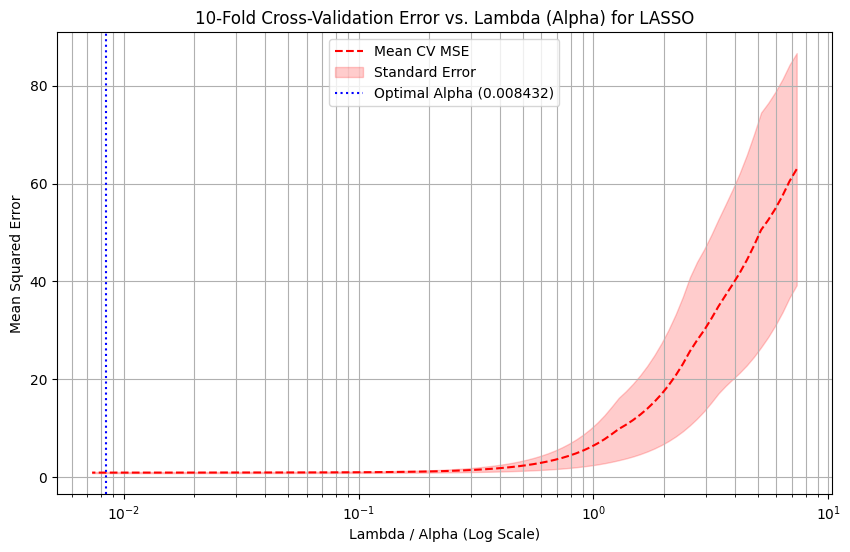

De-standardized (Original Scale) LASSO Intercept: -8.1733

De-standardized (Original Scale) LASSO Coefficients:
X^1    : 4.0228
X^2    : -2.7579
X^3    : 0.9324
X^4    : -0.0000
X^5    : 0.0000
X^6    : -0.0000
X^7    : 0.0000
X^8    : -0.0000
X^9    : 0.0000
X^10   : -0.0001
Length of new Y: 100
First 5 elements of new Y: [-9.40791062 -8.42064629 -8.29489959 10.20670734 -8.1613243 ]
Running Forward Stepwise Selection on the new target (Y = b0 + b7*X^7 + e):
Selected X^7    | New BIC: 281.7190
Selected X^2    | New BIC: 280.3979

Final selected predictors for the new model: ['X^7', 'X^2']
Optimal Alpha (Lambda) for Y_new: 0.086749
De-standardized (Original Scale) LASSO Intercept: -8.0421

De-standardized (Original Scale) LASSO Coefficients:
X^1    : -0.0000
X^2    : 0.0000
X^3    : 0.0000
X^4    : -0.0000
X^5    : 0.4387
X^6    : -0.0000
X^7    : 0.7813
X^8    : -0.0000
X^9    : 0.0224
X^10   : -0.0000
Estimated sigma^2 (Full Model on Y_new): 0.8738

--- Forward Stepwise Model (X^7, X^

In [3]:
# Week 3, Applied Question 8.



# numerical Python
import numpy as np

# Set seed for reproducibility.
np.random.seed(42)

# Define sample size.
n = 100

# Generate predictor X and noise vector e.
X = np.random.normal(size=n)
e = np.random.normal(size=n)

# Confirm sample sizes.
print("Length of X:", len(X))
print("Length of e:", len(e))



# Generate response vector Y.
Y = -8 + 4 * X - 3 * (X ** 2) + 1 * (X ** 3) + e

# Confirm sample size of Y and show first five.
print("Length of Y:", len(Y))
print("First 5 elements of Y:", Y[:5])


# data import and statistical methods
import pandas as pd
import statsmodels.api as sm

# Create a dataFrame containing predictors X, X^2, ..., X^10.
data = pd.DataFrame({f'X^{i}': X**i for i in range(1, 11)})
data['Y'] = Y

# forward stepwise regression
def forward_stepwise_selection(df, response_col):
    remaining_predictors = [col for col in df.columns if col != response_col]
    selected_predictors = []
    current_score, best_new_score = float('inf'), float('inf')

    step_records = []

    while remaining_predictors:
        scores_with_candidates = []
        for candidate in remaining_predictors:
            features = selected_predictors + [candidate]
            # Fit OLS regression with intercept
            X_design = sm.add_constant(df[features])
            model = sm.OLS(df[response_col], X_design).fit()
            # Using BIC as the selection criterion
            score = model.bic
            scores_with_candidates.append((score, candidate))

        scores_with_candidates.sort()
        best_new_score, best_candidate = scores_with_candidates[0]

        if len(selected_predictors) == 0 or best_new_score < current_score:
            remaining_predictors.remove(best_candidate)
            selected_predictors.append(best_candidate)
            current_score = best_new_score
            step_records.append((list(selected_predictors), current_score))
            print(f"Selected {best_candidate:<6} | New BIC: {current_score:.4f}")
        else:
            break

    return selected_predictors, step_records

best_features, steps = forward_stepwise_selection(data, 'Y')
print("\nFinal selected predictors:", best_features)


# Fit the full model containing all 10 predictors to estimate true sigma^2.
X_full = sm.add_constant(data[[f'X^{i}' for i in range(1, 11)]])
full_model = sm.OLS(data['Y'], X_full).fit()
sigma_sq_est = full_model.mse_resid  # This is the estimate of true variance

# Fit the selected stepwise model (X^1, X^2, X^3)
X_selected = sm.add_constant(data[best_features])
selected_model = sm.OLS(data['Y'], X_selected).fit()

# Calculate Mallows' Cp = (RSS_d / sigma_sq_est) - n + 2p
# p is the number of parameters including the intercept.
n_obs = len(Y)
p_params = len(best_features) + 1  # Predictors + intercept
rss_selected = selected_model.ssr

cp = (rss_selected / sigma_sq_est) - n_obs + 2 * p_params

print(f"Residual Sum of Squares (RSS) for selected model: {rss_selected:.4f}")
print(f"Estimated sigma^2 from full model: {sigma_sq_est:.4f}")
print(f"Number of parameters (p): {p_params}")
print(f"Mallows' Cp statistic: {cp:.4f}")


# Fit the final model using the chosen predictors
# Based on the output, the selected predictors are ['X^3', 'X^2', 'X^1']
final_features = ['X^3', 'X^2', 'X^1']

# Add the constant (intercept) to the design matrix
X_final = sm.add_constant(data[final_features])

# Fit the final OLS model
final_model = sm.OLS(data['Y'], X_final).fit()

# Display the coefficients and intercept
print("\n--- Final Model Parameters ---")
print(final_model.params)




# backward stepwise regression
def backward_stepwise_selection(df, response_col):
    # Start with all 10 predictors
    selected_predictors = [col for col in df.columns if col != response_col]

    # Fit initial full model
    X_design = sm.add_constant(df[selected_predictors])
    current_model = sm.OLS(df[response_col], X_design).fit()
    current_score = current_model.bic

    print(f"Initial Full Model BIC: {current_score:.4f}")

    step_records = [(list(selected_predictors), current_score)]

    while len(selected_predictors) > 1:
        scores_with_eliminations = []

        # Try removing each predictor one by one
        for candidate in selected_predictors:
            features = [col for col in selected_predictors if col != candidate]
            X_design = sm.add_constant(df[features])
            model = sm.OLS(df[response_col], X_design).fit()
            score = model.bic
            scores_with_eliminations.append((score, candidate))

        # Find the elimination that yields the lowest BIC
        scores_with_eliminations.sort()
        best_new_score, worst_candidate = scores_with_eliminations[0]

        if best_new_score < current_score:
            selected_predictors.remove(worst_candidate)
            current_score = best_new_score
            step_records.append((list(selected_predictors), current_score))
            print(f"Removed {worst_candidate:<6} | New BIC: {current_score:.4f}")
        else:
            # No improvement by removing any predictor
            break

    return selected_predictors, step_records

backward_features, backward_steps = backward_stepwise_selection(data, 'Y')
print("\nFinal selected predictors (Backward):", backward_features)


# Fit the backward selection model
X_selected_backward = sm.add_constant(data[backward_features])
backward_model = sm.OLS(data['Y'], X_selected_backward).fit()

# Calculate Mallows' Cp for backward selection model
# using the sigma^2 estimated from the full 10-predictor model (sigma_sq_est).
p_params_backward = len(backward_features) + 1  # Predictors + intercept
rss_backward = backward_model.ssr

cp_backward = (rss_backward / sigma_sq_est) - n_obs + 2 * p_params_backward

print(f"Residual Sum of Squares (RSS) for backward model: {rss_backward:.4f}")
print(f"Estimated sigma^2 from full model: {sigma_sq_est:.4f}")
print(f"Number of parameters (p): {p_params_backward}")
print(f"Mallows' Cp statistic for backward model: {cp_backward:.4f}")


# backward_stepwise_selection(data, 'Y')

# 2. Fit the final model using the chosen predictors
# Based on the output, the selected predictors are ['X^3', 'X^2', 'X^1']
final_features = ['X^3', 'X^2', 'X^1']

# Add the constant (intercept) to the design matrix
X_final = sm.add_constant(data[final_features])

# Fit the final OLS model
final_model = sm.OLS(data['Y'], X_final).fit()

# 3. Display the coefficients and intercept
print("\n--- Final Model Parameters ---")
print(final_model.params)



# Scikit-Learn is the open-source library for ML.
# Lasso = Least Absolute Shrinkage and Selection Operator.
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

# Separate features and target.
X_features = data[[f'X^{i}' for i in range(1, 11)]]
Y_target = data['Y']

# Standardize features (LASSO scale affects regularization).
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_features)

# Fit LASSO model using cross-validation to select optimal lambda.
lasso_cv = LassoCV(cv=10, random_state=42, max_iter=100000)
lasso_cv.fit(X_scaled, Y_target)

# Extract coefficients and map them back to the original scale.
coefficients = lasso_cv.coef_
intercept = lasso_cv.intercept_

print(f"Optimal Alpha: {lasso_cv.alpha_:.6f}")
print(f"Intercept: {intercept:.4f}")
print("\nLASSO Coefficients:")
for name, coef in zip(X_features.columns, coefficients):
    print(f"{name:<6} : {coef:.4f}")


# data visualization module
import matplotlib.pyplot as plt

# LassoCV already calculated the CV path since cv=10.
# MSE path is shape (n_alphas, n_folds)
mse_path = lasso_cv.mse_path_
alphas = lasso_cv.alphas_

# Calculate the mean and standard error of the MSE across folds for each alpha (lambda).
mean_mse = mse_path.mean(axis=1)
std_mse = mse_path.std(axis=1) / np.sqrt(lasso_cv.cv if isinstance(lasso_cv.cv, int) else 10)

# Plot cross-validation error as a function of alpha.
plt.figure(figsize=(10, 6))
plt.semilogx(alphas, mean_mse, 'r--', label='Mean CV MSE')
plt.fill_between(alphas, mean_mse - std_mse, mean_mse + std_mse, alpha=0.2, color='red', label='Standard Error')

# Add line for optimal alpha.
plt.axvline(lasso_cv.alpha_, linestyle=':', color='blue', label=f'Optimal Alpha ({lasso_cv.alpha_:.6f})')

plt.xlabel('Lambda / Alpha (Log Scale)')
plt.ylabel('Mean Squared Error')
plt.title('10-Fold Cross-Validation Error vs. Lambda (Alpha) for LASSO')
plt.legend()
plt.grid(True, which="both", ls="-")
plt.show()


# Map scaled coefficients back to the original scale.
# Beta_orig = Beta_scaled / std(X)
# Intercept_orig = Intercept_scaled - sum(Beta_scaled * mean(X) / std(X))

means = scaler.mean_
scales = scaler.scale_

original_coefficients = coefficients / scales
original_intercept = intercept - np.sum(coefficients * means / scales)

print(f"De-standardized (Original Scale) LASSO Intercept: {original_intercept:.4f}")
print("\nDe-standardized (Original Scale) LASSO Coefficients:")
for name, coef in zip(X_features.columns, original_coefficients):
    print(f"{name:<6} : {coef:.4f}")

# Generate response vector Y according to the model: Y = b0 + b7 * X^7 + e.
# Use b0 = -8 and b7 = 1 for consistency.
b0 = -8
b7 = 1

Y_new = b0 + b7 * (X ** 7) + e

print("Length of new Y:", len(Y_new))
print("First 5 elements of new Y:", Y_new[:5])


# Create a new DataFrame with the same features but using the new target Y_new.
data_new = pd.DataFrame({f'X^{i}': X**i for i in range(1, 11)})
data_new['Y_new'] = Y_new

# Perform forward stepwise selection using the previously defined function.
print("Running Forward Stepwise Selection on the new target (Y = b0 + b7*X^7 + e):")
best_features_new, steps_new = forward_stepwise_selection(data_new, 'Y_new')

print("\nFinal selected predictors for the new model:", best_features_new)


# Use the same standardized features (X_scaled) calculated from X_features.
# Fit LASSO model using Cross-Validation to select optimal alpha for Y_new.
lasso_cv_new = LassoCV(cv=10, random_state=42, max_iter=100000)
lasso_cv_new.fit(X_scaled, Y_new)

# Extract coefficients.
coefficients_new = lasso_cv_new.coef_
intercept_new = lasso_cv_new.intercept_

# Map scaled coefficients back to the original scale.
means = scaler.mean_
scales = scaler.scale_

original_coefficients_new = coefficients_new / scales
original_intercept_new = intercept_new - np.sum(coefficients_new * means / scales)

print(f"Optimal Alpha (Lambda) for Y_new: {lasso_cv_new.alpha_:.6f}")
print(f"De-standardized (Original Scale) LASSO Intercept: {original_intercept_new:.4f}")
print("\nDe-standardized (Original Scale) LASSO Coefficients:")
for name, coef in zip(X_features.columns, original_coefficients_new):
    print(f"{name:<6} : {coef:.4f}")


# Fit the full model on Y_new with all 10 predictors to estimate true sigma^2.
X_full_new = sm.add_constant(data_new[[f'X^{i}' for i in range(1, 11)]])
full_model_new = sm.OLS(data_new['Y_new'], X_full_new).fit()
sigma_sq_est_new = full_model_new.mse_resid

n_obs = len(Y_new)

# Cp for Forward Stepwise Selection (selected features: best_features_new).
X_selected_fw_new = sm.add_constant(data_new[best_features_new])
fw_model_new = sm.OLS(data_new['Y_new'], X_selected_fw_new).fit()

p_fw = len(best_features_new) + 1  # Predictors + intercept
rss_fw = fw_model_new.ssr
cp_fw = (rss_fw / sigma_sq_est_new) - n_obs + 2 * p_fw

# Cp for LASSO model
# Identify non-zero coefficients in LASSO (predictors that were selected)
# We'll use a small threshold to determine non-zero coefficients
threshold = 1e-4
lasso_selected_features = [f'X^{i}' for i, coef in enumerate(original_coefficients_new, 1) if abs(coef) > threshold]

# Fit the OLS model using LASSO-selected features to calculate RSS/Cp
if len(lasso_selected_features) > 0:
    X_selected_lasso_new = sm.add_constant(data_new[lasso_selected_features])
    lasso_ols_model = sm.OLS(data_new['Y_new'], X_selected_lasso_new).fit()
    rss_lasso = lasso_ols_model.ssr
    p_lasso = len(lasso_selected_features) + 1
else:
    # Intercept only model if LASSO shrank all coefficients to zero
    X_selected_lasso_new = sm.add_constant(np.ones((n_obs, 1)))
    lasso_ols_model = sm.OLS(data_new['Y_new'], X_selected_lasso_new).fit()
    rss_lasso = lasso_ols_model.ssr
    p_lasso = 1

cp_lasso = (rss_lasso / sigma_sq_est_new) - n_obs + 2 * p_lasso

print(f"Estimated sigma^2 (Full Model on Y_new): {sigma_sq_est_new:.4f}\n")
print(f"--- Forward Stepwise Model ({', '.join(best_features_new)}) ---")
print(f"Residual Sum of Squares (RSS): {rss_fw:.4f}")
print(f"Number of parameters (p): {p_fw}")
print(f"Mallows' Cp statistic: {cp_fw:.4f}\n")

print(f"--- LASSO Model ({', '.join(lasso_selected_features) if lasso_selected_features else 'Intercept only'}) ---")
print(f"Residual Sum of Squares (RSS): {rss_lasso:.4f}")
print(f"Number of parameters (p): {p_lasso}")
print(f"Mallows' Cp statistic: {cp_lasso:.4f}")



